# Defense Gene Z Score Distribution (Plates 1–5)

Histogram of the defense activation score for the plates 1–5 transcriptome samples (seasonal + circadian, replicates removed).

- **Defense genes:** the 148-gene list from `load_correlated_immunity_genes_plates_1_to_5.ipynb` (defense GO-term and FLG genes with Pearson r > 0.4 vs total load on plates 1–5).
- **Score:** each gene is z-scored across all samples, and the score is the sum of z-scores divided by the number of genes, as in `dysbiosis_calls_and_defense_score_recalled_genera.ipynb`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

In [2]:
transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_tpm_normalized.csv",
    index_col=0,
)
rows_to_drop_expression_data = [
    "A2450525897_n01_undetermined",
    "A2449446903_n01_undetermined",
    "B250508004_n01_undetermined",
    "B2449500127_n01_undetermined",
]
transcriptome = transcriptome.drop(index=rows_to_drop_expression_data)
transcriptome = transcriptome.sort_index()
metadata = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Plates_1_to_5_metadata_merged_luke.csv",
    index_col=0,
)
metadata = metadata.drop(
    columns=[
        "arb.sort",
        "sample-id",
        "Ambiguous Unstranded",
        "Ambiguous Forward",
        "Multimapping",
        "Unmapped Over Mapped",
    ]
)
metadata["Date and Time"] = metadata["date"] + " " + metadata["time"]
luke_time_data_format = "%-m/%-d/%y %-H:%-M"
metadata["Date and Time"] = pd.to_datetime(
    metadata["Date and Time"], format=luke_time_data_format
)

## Get plate 5 samples and remove what they replaced from the metadata to avoid duplicates
plate_5_replacements = metadata.loc[metadata["rnaprepplate"] == "LICRNA_05"]
non_plate_5_samples = metadata.loc[metadata["rnaprepplate"] != "LICRNA_05"]
replaced_samples = non_plate_5_samples.loc[
    non_plate_5_samples["sampID"].isin(plate_5_replacements["sampID"])
]
trimmed_metadata = metadata.drop(index=replaced_samples.index)
### For remaining duplicated sampIDs, drop the transcriptome with fewer total reads
double_duplicates = (
    trimmed_metadata.loc[trimmed_metadata.duplicated(subset="sampID", keep=False)]
    .sort_values(by="Total Reads")
    .drop_duplicates(subset="sampID", keep="first")
)
trimmed_metadata = trimmed_metadata.drop(index=double_duplicates.index)
### Drop failed libraries with too few reads (e.g. LIC162 has 66 total reads)
min_total_reads = 250_000
low_read_samples = trimmed_metadata.index[trimmed_metadata["Total Reads"] < min_total_reads]
trimmed_metadata = trimmed_metadata.drop(index=low_read_samples)
print(f"Dropped {len(low_read_samples)} transcriptomes with < {min_total_reads:,} total reads")
trimmed_transcriptome = transcriptome.loc[trimmed_metadata.index]
print("Transcriptomes after removing replicates:", len(trimmed_metadata))
defense_gene_list = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/load_correlated_genes_union_GO_and_FLG_plates_1_to_5.csv"
)

Dropped 6 transcriptomes with < 250,000 total reads
Transcriptomes after removing replicates: 426


In [3]:
transcriptome_in_defense_gene_list = trimmed_transcriptome.loc[
    :, trimmed_transcriptome.columns.isin(defense_gene_list["gene"])
]
print("Defense genes in transcriptome:", transcriptome_in_defense_gene_list.shape[1], "of", len(defense_gene_list))

trimmed_metadata["Defense Z Score"] = transcriptome_in_defense_gene_list.apply(zscore).sum(
    axis=1
) / len(defense_gene_list)
trimmed_metadata["Seasonal_or_circadian"] = np.where(
    trimmed_metadata["Experiment Type"] == "Long Term", "Seasonal", "Circadian"
)
trimmed_metadata.groupby("Seasonal_or_circadian")["Defense Z Score"].describe(
    percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]
)

Defense genes in transcriptome: 148 of 148


,count,mean,std,min,5%,25%,50%,75%,95%,max
Seasonal_or_circadian,,,,,,,,,,
Circadian,203.0,-0.105738,0.417833,-0.731088,-0.601673,-0.427287,-0.177452,0.135822,0.766990,1.336750
Seasonal,223.0,0.096255,0.722622,-0.824740,-0.673866,-0.369720,-0.080101,0.366209,1.300971,5.237776


Samples: 426


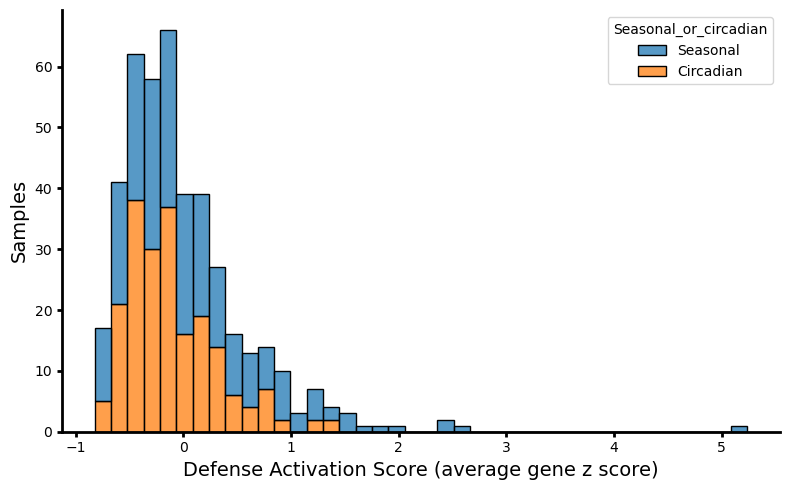

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor("white")
sns.histplot(
    data=trimmed_metadata,
    x="Defense Z Score",
    hue="Seasonal_or_circadian",
    multiple="stack",
    bins=40,
    ax=ax,
)
plt.xlabel("Defense Activation Score (average gene z score)", fontsize=14)
plt.ylabel("Samples", fontsize=14)
sns.despine()
ax.spines["bottom"].set_color("black")
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_color("black")
ax.spines["left"].set_linewidth(2)
ax.tick_params(axis="both", width=2)
plt.tight_layout()

print(f"Samples: {trimmed_metadata['Defense Z Score'].notna().sum()}")

## Differential expression: defense score > 1 vs the rest

DESeq2 with `~timepoint + group` on all transcriptome samples, comparing samples with a defense score above `high_defense_threshold` to all others. Gene filters as in the dysbiosis DE notebooks (> 2000 total reads, > 1 read in more than 21 samples).

The groups are defined from the expression of the 148 defense genes, so those genes are expected to come out as DE. The genes of interest are the significant ones *outside* the defense set.

In [5]:
import contextlib
import io
import pydeseq2.default_inference
import pydeseq2.ds
import pydeseq2.dds

high_defense_threshold = 1.0
expressed_gene_reads_threshold = 2000
number_of_samples_expressed_in_threshold = 21

raw_transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_for_norm.csv",
    index_col=0,
)
de_counts = raw_transcriptome.loc[trimmed_metadata.index]
de_counts = de_counts.loc[:, de_counts.sum() > expressed_gene_reads_threshold]
de_counts = de_counts.loc[:, (de_counts > 1).sum() > number_of_samples_expressed_in_threshold]

trimmed_metadata["Defense Group"] = np.where(
    trimmed_metadata["Defense Z Score"] > high_defense_threshold, "High", "Rest"
)
print("Genes tested:", de_counts.shape[1])
pd.crosstab(trimmed_metadata["Seasonal_or_circadian"], trimmed_metadata["Defense Group"], margins=True)

Genes tested: 18032


Defense Group,High,Rest,All
Seasonal_or_circadian,,,
Circadian,4,199,203
Seasonal,20,203,223
All,24,402,426


In [6]:
inference = pydeseq2.default_inference.DefaultInference(n_cpus=6)
with contextlib.redirect_stdout(io.StringIO()):
    dds = pydeseq2.dds.DeseqDataSet(
        counts=de_counts,
        metadata=trimmed_metadata[["timepoint", "Defense Group"]].rename(
            columns={"Defense Group": "defense_group"}
        ),
        design="~timepoint+defense_group",
        refit_cooks=True,
        inference=inference,
        quiet=True,
    )
    dds.deseq2()
    stats = pydeseq2.ds.DeseqStats(
        dds, contrast=["defense_group", "High", "Rest"], inference=inference, quiet=True
    )
    stats.summary()
high_defense_results = stats.results_df
high_defense_results["in defense gene set"] = high_defense_results.index.isin(
    defense_gene_list["gene"]
)
high_defense_significant = high_defense_results.loc[high_defense_results["padj"] < 0.05]

high_defense_results.to_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/deseq_high_defense_score_vs_rest.csv"
)
print(f"Significant genes (padj < 0.05): {len(high_defense_significant)}")
print(f"  up in high-defense samples: {(high_defense_significant['log2FoldChange'] > 0).sum()}")
print(f"  down: {(high_defense_significant['log2FoldChange'] < 0).sum()}")
print(
    f"  in the 148-gene defense set: {high_defense_significant['in defense gene set'].sum()} "
    f"(of {high_defense_results['in defense gene set'].sum()} defense genes tested)"
)
print(f"  outside the defense set: {(~high_defense_significant['in defense gene set']).sum()}")

Significant genes (padj < 0.05): 3084
  up in high-defense samples: 1681
  down: 1403
  in the 148-gene defense set: 73 (of 146 defense genes tested)
  outside the defense set: 3011


In [7]:
# Significant genes outside the defense set
high_defense_significant.loc[
    ~high_defense_significant["in defense gene set"], ["baseMean", "log2FoldChange", "padj"]
].sort_values("padj").head(50)

,baseMean,log2FoldChange,padj
AT2G38860,496.945161,1.330979,5.972975e-10
AT3G26520,6939.374328,-1.025091,5.972975e-10
AT3G20820,448.920769,-0.664940,5.972975e-10
AT3G63160,4887.975577,-0.694537,7.605309e-10
ArthCp060,5254.859065,-1.019771,1.757217e-09
AT5G07370,227.366453,-0.747757,1.757217e-09
AT2G38540,6059.604237,-0.663012,3.634054e-09
AT2G39800,477.875968,-1.428098,4.552680e-09
AT3G27830,1604.008332,-0.711595,4.552680e-09
AT1G76990,437.067281,0.815482,5.278847e-09


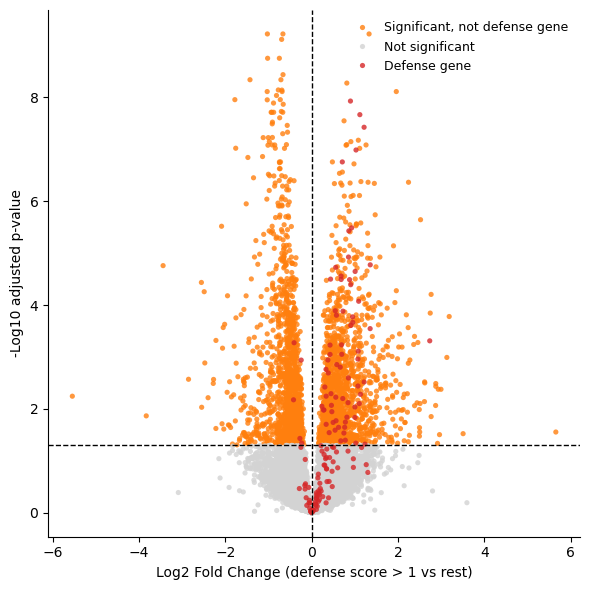

In [8]:
volcano_df = high_defense_results[["log2FoldChange", "padj", "in defense gene set"]].replace(
    [np.inf, -np.inf], np.nan
).dropna()
volcano_df["neg_log10_padj"] = -np.log10(volcano_df["padj"].clip(lower=1e-300))
volcano_df["category"] = np.select(
    [
        volcano_df["in defense gene set"],
        volcano_df["padj"] < 0.05,
    ],
    ["Defense gene", "Significant, not defense gene"],
    default="Not significant",
)

fig, ax = plt.subplots(figsize=(6, 6))
fig.patch.set_facecolor("white")
sns.scatterplot(
    data=volcano_df.sort_values("category", ascending=False),
    x="log2FoldChange",
    y="neg_log10_padj",
    hue="category",
    palette={
        "Not significant": "lightgray",
        "Significant, not defense gene": "tab:orange",
        "Defense gene": "tab:red",
    },
    alpha=0.8,
    s=14,
    linewidth=0,
    ax=ax,
)
ax.axhline(-np.log10(0.05), linestyle="--", color="black", linewidth=1)
ax.axvline(0, linestyle="--", color="black", linewidth=1)
ax.set_xlabel("Log2 Fold Change (defense score > 1 vs rest)")
ax.set_ylabel("-Log10 adjusted p-value")
ax.legend(frameon=False, fontsize=9)
sns.despine()
plt.tight_layout()

## GO enrichment of the high-defense DE genes

Significant genes (padj < 0.05) **outside** the 148-gene defense set, split into up- and downregulated in high-defense samples. The background is every gene tested by DESeq2, minus the defense set, so the enrichment isn't driven by the genes used to define the groups. Each list is tested separately for biological process, molecular function and cellular component, as in `go_term_enrichment_dysbiosis_recalled_genera.ipynb`.

In [9]:
import json
import Go_tools

non_defense = ~high_defense_results["in defense gene set"]
go_gene_lists = {
    "Up in high-defense": high_defense_results.index[
        non_defense & (high_defense_results["padj"] < 0.05) & (high_defense_results["log2FoldChange"] > 0)
    ].tolist(),
    "Down in high-defense": high_defense_results.index[
        non_defense & (high_defense_results["padj"] < 0.05) & (high_defense_results["log2FoldChange"] < 0)
    ].tolist(),
}
go_background_genes = high_defense_results.index[non_defense].tolist()
for name, genes in go_gene_lists.items():
    print(f"{name}: {len(genes)} genes")
print(f"Background: {len(go_background_genes)} genes")

go_term_matrix = pd.read_csv(
    "/Users/michael/Data/Reference_data/Arabdidopsis_go_matrix_from_tair_gaf.csv",
    index_col=0,
)
go_term_names = pd.read_csv(
    "/Users/michael/Data/Reference_data/goterm_names.csv", index_col=0
)

# GO namespace of every term, from go-basic.json (as in the original GO notebook)
gobasic = json.load(open("/Users/michael/Data/Reference_data/go-basic.json", "r"))
namespace_by_term = {}
for go_term in gobasic["graphs"][0].get("nodes", []):
    go_number = go_term.get("id", "").rsplit("/", 1)[-1].replace("GO_", "")
    if not go_number.isdigit():
        continue
    for property_value in go_term.get("meta", {}).get("basicPropertyValues", []):
        if property_value.get("pred", "").endswith("#hasOBONamespace"):
            namespace_by_term[f"GO:{int(go_number):07d}"] = property_value.get("val")
            break
term_namespace = pd.Series(namespace_by_term)
namespaces = ["biological_process", "molecular_function", "cellular_component"]

Up in high-defense: 1613 genes
Down in high-defense: 1398 genes
Background: 17886 genes


In [10]:
def run_go_enrichment(gene_list, go_annotations):
    with contextlib.redirect_stdout(io.StringIO()):
        cont_tables = Go_tools.generate_contigency_tables(
            go_annotations=go_annotations,
            gene_list=gene_list,
            use_background_genes=True,
            background_genes=go_background_genes,
        )
        fishers_results = Go_tools.fishers_exact_on_contigency_tables(
            all_go_contigency_tables=cont_tables,
            original_GO_term_panda=go_annotations,
        )
        corrected = Go_tools.multi_hypothesis_correct_fishers_exact(fishers_results)
    named = corrected.merge(go_term_names, left_index=True, right_index=True, how="left")
    named["x"] = named["x"].str.capitalize()
    named["Neg Log P Val"] = -np.log10(named["P_value"].clip(lower=1e-300))
    return named.sort_values("P_value")


high_defense_go = {}
for list_name, gene_list in go_gene_lists.items():
    for namespace in namespaces:
        terms = term_namespace.index[term_namespace == namespace]
        high_defense_go[(list_name, namespace)] = run_go_enrichment(
            gene_list, go_term_matrix.loc[:, go_term_matrix.columns.isin(terms)]
        )

pd.DataFrame(
    {
        f"{list_name} | {namespace}": {
            "terms with corrected P < 0.05": int((results["P_value"] < 0.05).sum())
        }
        for (list_name, namespace), results in high_defense_go.items()
    }
).T

,terms with corrected P < 0.05
Up in high-defense | biological_process,21
Up in high-defense | molecular_function,4
Up in high-defense | cellular_component,4
Down in high-defense | biological_process,34
Down in high-defense | molecular_function,7
Down in high-defense | cellular_component,42


In [11]:
for (list_name, namespace), results in high_defense_go.items():
    print(f"\n=== {list_name} | {namespace} ===")
    display(results.loc[:, ["x", "P_value"]].head(15))


=== Up in high-defense | biological_process ===


,x,P_value
GO:0042742,Defense response to bacterium,1.697443e-12
GO:0009751,Response to salicylic acid,2.386728e-08
GO:0071456,Cellular response to hypoxia,3.217637e-08
GO:0009617,Response to bacterium,4.722545e-07
GO:0006979,Response to oxidative stress,4.722545e-07
GO:0050832,Defense response to fungus,4.197067e-06
GO:0009620,Response to fungus,1.758332e-05
GO:0002239,Response to oomycetes,1.835206e-05
GO:0010120,Camalexin biosynthetic process,8.192974e-05
GO:0006952,Defense response,4.090794e-04



=== Up in high-defense | molecular_function ===


,x,P_value
GO:0030275,Lrr domain binding,0.000016
GO:0016301,Kinase activity,0.005622
GO:0015211,Purine nucleoside transmembrane transporter ac...,0.021225
GO:0033612,Receptor serine/threonine kinase binding,0.026419
GO:0035251,Udp-glucosyltransferase activity,0.058624
GO:0005509,Calcium ion binding,0.058624
GO:0005516,Calmodulin binding,0.102525
GO:0005345,Purine nucleobase transmembrane transporter ac...,0.102525
GO:0005515,Protein binding,0.412844
GO:0043531,Adp binding,0.412844



=== Up in high-defense | cellular_component ===


...

,x,P_value
GO:0006412,Translation,1.453656e-25
GO:0015979,Photosynthesis,3.871516e-11
GO:0009658,Chloroplast organization,2.116498e-10
GO:0015995,Chlorophyll biosynthetic process,2.116498e-10
GO:0009409,Response to cold,8.391039e-10
GO:0009768,"Photosynthesis, light harvesting in photosystem i",2.833382e-09
GO:0009645,Response to low light intensity stimulus,3.054010e-07
GO:0009644,Response to high light intensity,9.838773e-07
GO:0009416,Response to light stimulus,1.285570e-06
GO:0009773,Photosynthetic electron transport in photosyst...,8.961311e-06



=== Down in high-defense | molecular_function ===


,x,P_value
GO:0003729,Mrna binding,2.522782e-51
GO:0016168,Chlorophyll binding,3.233193e-13
GO:0003735,Structural constituent of ribosome,2.040786e-08
GO:0009055,Electron transfer activity,2.725396e-05
GO:0015250,Water channel activity,1.766070e-04
GO:0016851,Magnesium chelatase activity,4.723312e-02
GO:0008266,Poly(u) rna binding,4.723312e-02
GO:1901149,Salicylic acid binding,5.075475e-02
GO:0008047,Enzyme activator activity,7.278793e-02
GO:0051920,Peroxiredoxin activity,9.434420e-02



=== Down in high-defense | cellular_component ===


,x,P_value
GO:0009507,Chloroplast,3.722867e-102
GO:0009579,Thylakoid,3.847268e-98
GO:0009941,Chloroplast envelope,3.847268e-98
GO:0009570,Chloroplast stroma,8.801856e-93
GO:0009535,Chloroplast thylakoid membrane,9.804770e-92
GO:0009534,Chloroplast thylakoid,8.004701e-77
GO:0048046,Apoplast,3.421963e-33
GO:0009536,Plastid,6.501521e-24
GO:0009543,Chloroplast thylakoid lumen,1.995829e-23
GO:0005829,Cytosol,3.556190e-23


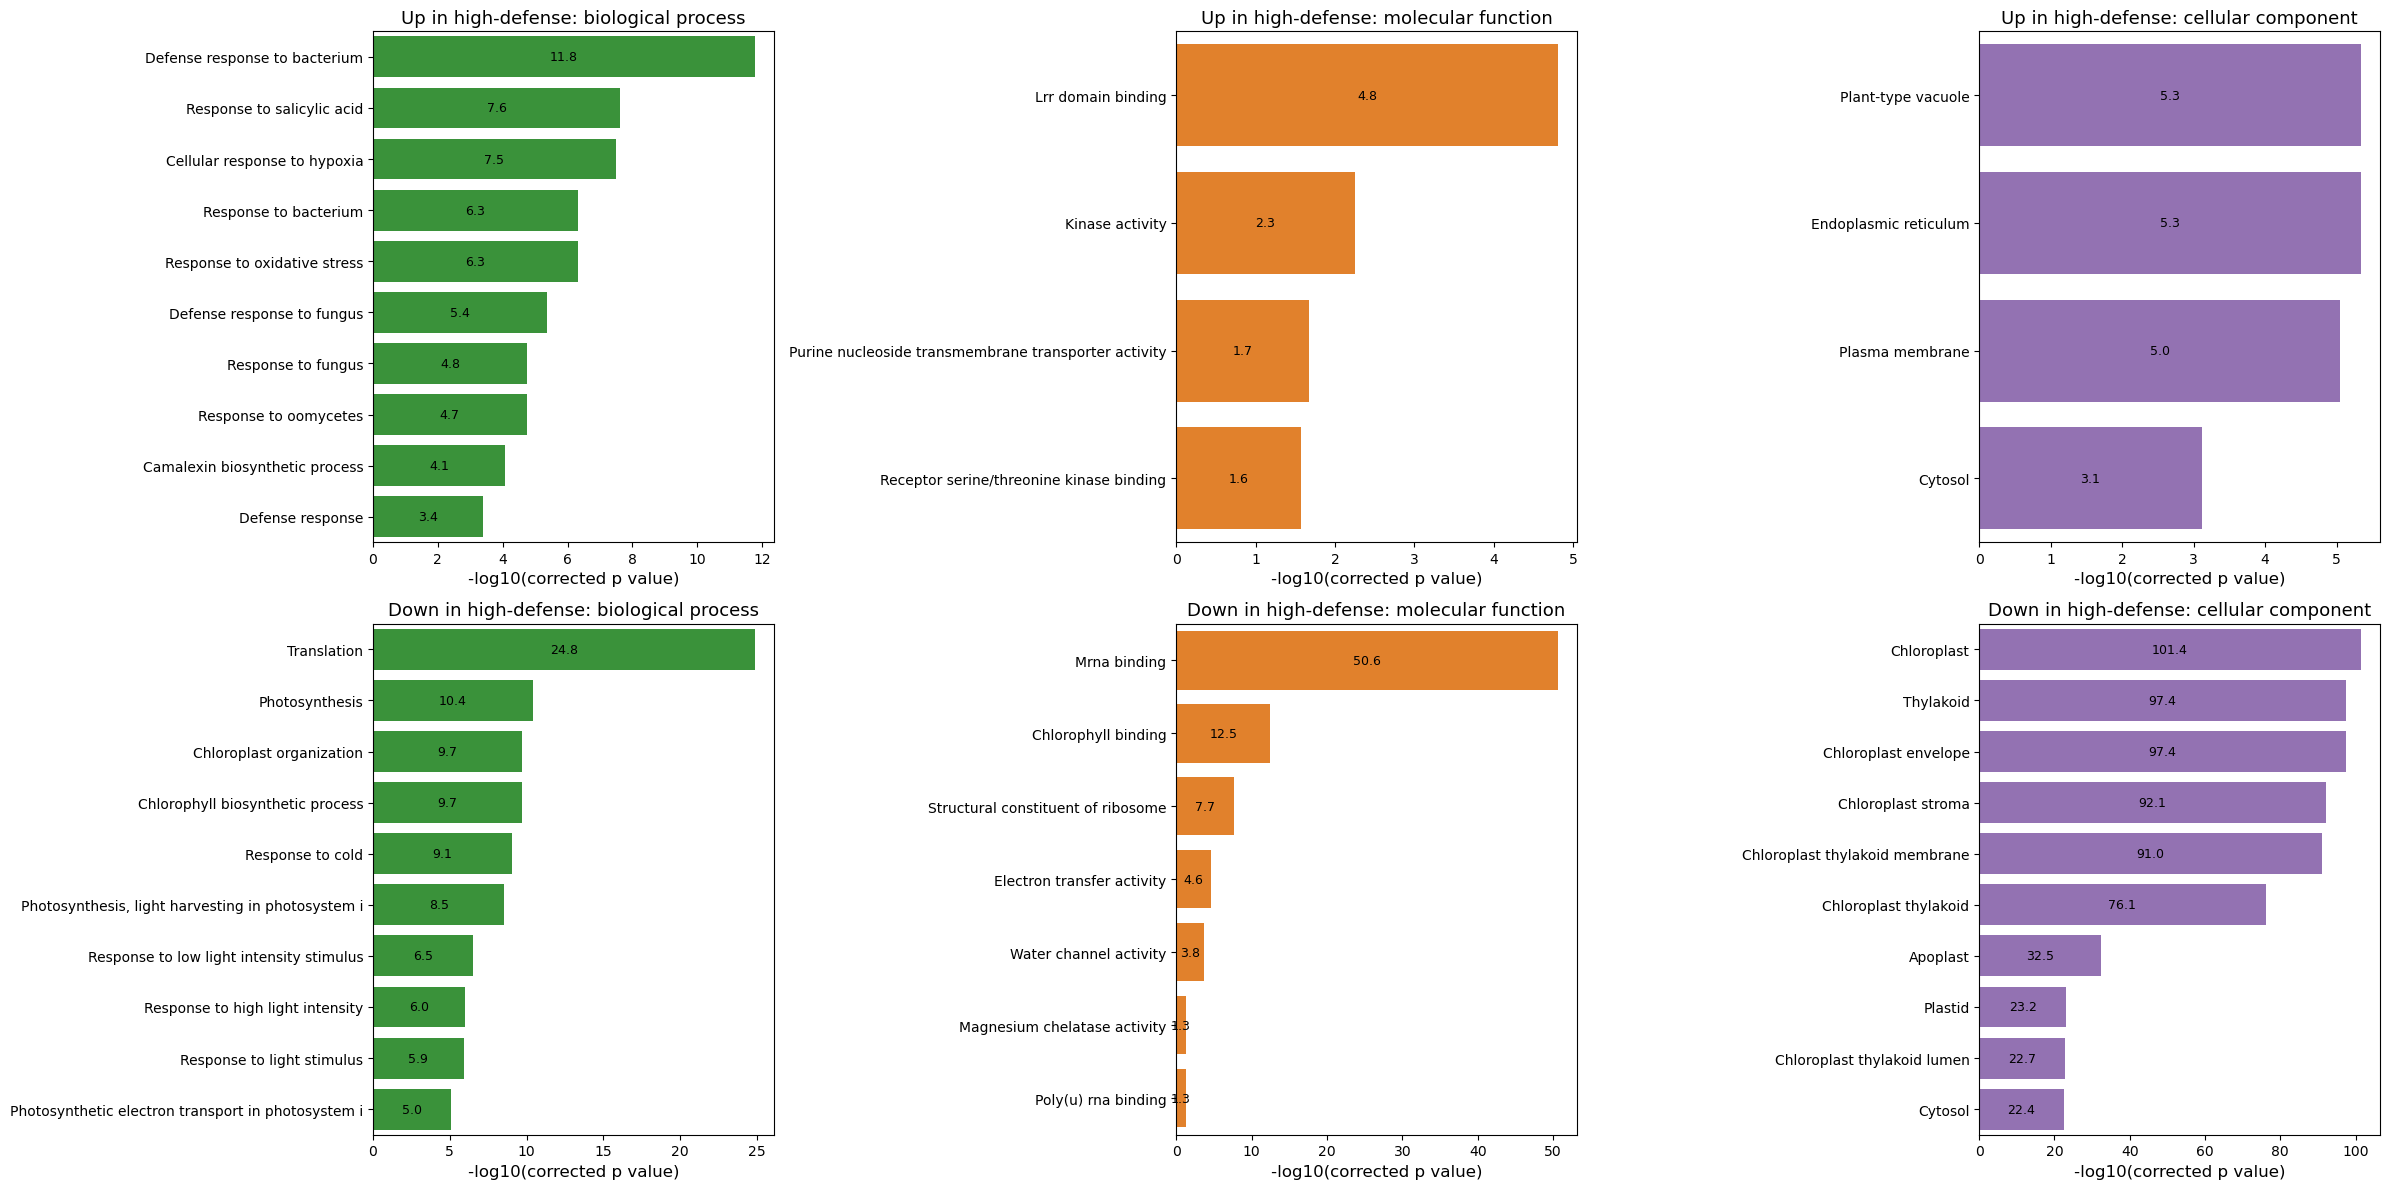

In [12]:
namespace_colors = {
    "biological_process": "tab:green",
    "molecular_function": "tab:orange",
    "cellular_component": "tab:purple",
}
fig, axes = plt.subplots(2, 3, figsize=(24, 12))
fig.patch.set_facecolor("white")
for row, list_name in enumerate(go_gene_lists):
    for col, namespace in enumerate(namespaces):
        ax = axes[row, col]
        plot_df = high_defense_go[(list_name, namespace)].dropna(subset=["x"]).head(10)
        plot_df = plot_df.loc[plot_df["P_value"] < 0.05]
        if plot_df.empty:
            ax.text(0.5, 0.5, "No terms with corrected P < 0.05", ha="center", va="center")
            ax.axis("off")
        else:
            g = sns.barplot(data=plot_df, x="Neg Log P Val", y="x", color=namespace_colors[namespace], ax=ax)
            g.bar_label(g.containers[0], fmt="%.1f", label_type="center", fontsize=9)
            ax.set_xlabel("-log10(corrected p value)", fontsize=12)
            ax.set_ylabel("")
        ax.set_title(f"{list_name}: {namespace.replace('_', ' ')}", fontsize=13)
plt.tight_layout()

In [13]:
pd.concat(
    {f"{list_name} | {namespace}": results for (list_name, namespace), results in high_defense_go.items()},
    names=["gene list | namespace", "go_id"],
).to_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/go_enrichment_high_defense_score_vs_rest.csv"
)